# 02 — Exploratory Data Analysis

**Purpose**: Answer the 4 required EDA questions with visualizations.

**Questions**:
1. What is the highest rated movie in 2023? Balance ratings vs votes.
2. Who is the most popular actor in 2023?
3. What are the user-movie preference trends over the years?
4. Define a hit movie metric (business justification).

**Prerequisites**: Run `01_data_loading.ipynb` first to generate parquet files.

**Key decisions**:
- D008/D009: Actor popularity weighted by billing order, numVotes, rating
- D010: Min vote threshold configurable (default 500)
- D011: Hit metric two-mode (Full with ROI, Partial without)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Plotting config
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Paths
DATA_DIR = os.path.join('..', 'data')
FIGURES_DIR = os.path.join('..', 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Config (D010)
MIN_VOTE_THRESHOLD = 500

# Load data from parquet files (generated by 01_data_loading.ipynb)
print('Loading data from parquet files...')
movies = pd.read_parquet(os.path.join(DATA_DIR, 'movies_clean.parquet'))
actor_popularity = pd.read_parquet(os.path.join(DATA_DIR, 'actor_popularity.parquet'))
director_stats = pd.read_parquet(os.path.join(DATA_DIR, 'director_stats.parquet'))
print(f'  Movies: {len(movies):,} rows')
print(f'  Actors: {len(actor_popularity):,} rows')
print(f'  Directors: {len(director_stats):,} rows')

Loading data from parquet files...
  Movies: 71,056 rows
  Actors: 250,278 rows
  Directors: 5,054 rows


## Q1: Highest Rated Movie in 2023 + Ratings vs Votes Balance

**Approach**:
- Filter 2023 movies with >= MIN_VOTE_THRESHOLD votes
- Compute IMDB weighted rating (Bayesian average)
- Scatter plot: rating vs numVotes (log scale)
- Table: Top 10 by weighted rating

**Weighted Rating Formula** (IMDB Bayesian):
$$WR = \frac{v}{v+m} \cdot R + \frac{m}{v+m} \cdot C$$

Where:
- $R$ = movie's average rating
- $v$ = number of votes for the movie
- $m$ = minimum votes required (25th percentile)
- $C$ = mean rating across all movies

In [2]:
# Filter 2023 movies from already-loaded data
movies_2023 = movies[movies['startYear'] == 2023].copy()
print(f'2023 movies with >= {MIN_VOTE_THRESHOLD} votes: {len(movies_2023):,}')

# Compute weighted rating parameters
C = movies_2023['averageRating'].mean()  # Mean rating across all 2023 movies
m = movies_2023['numVotes'].quantile(0.25)  # 25th percentile of votes

print(f'\nWeighted Rating Parameters:')
print(f'  C (mean rating) = {C:.2f}')
print(f'  m (min votes, 25th pctl) = {m:.0f}')

# Compute weighted rating
v = movies_2023['numVotes']
R = movies_2023['averageRating']
movies_2023['weighted_rating'] = (v / (v + m)) * R + (m / (v + m)) * C

print(f'\nWeighted rating range: {movies_2023["weighted_rating"].min():.2f} - {movies_2023["weighted_rating"].max():.2f}')

2023 movies with >= 500 votes: 2,529

Weighted Rating Parameters:
  C (mean rating) = 6.02
  m (min votes, 25th pctl) = 853

Weighted rating range: 1.98 - 8.69


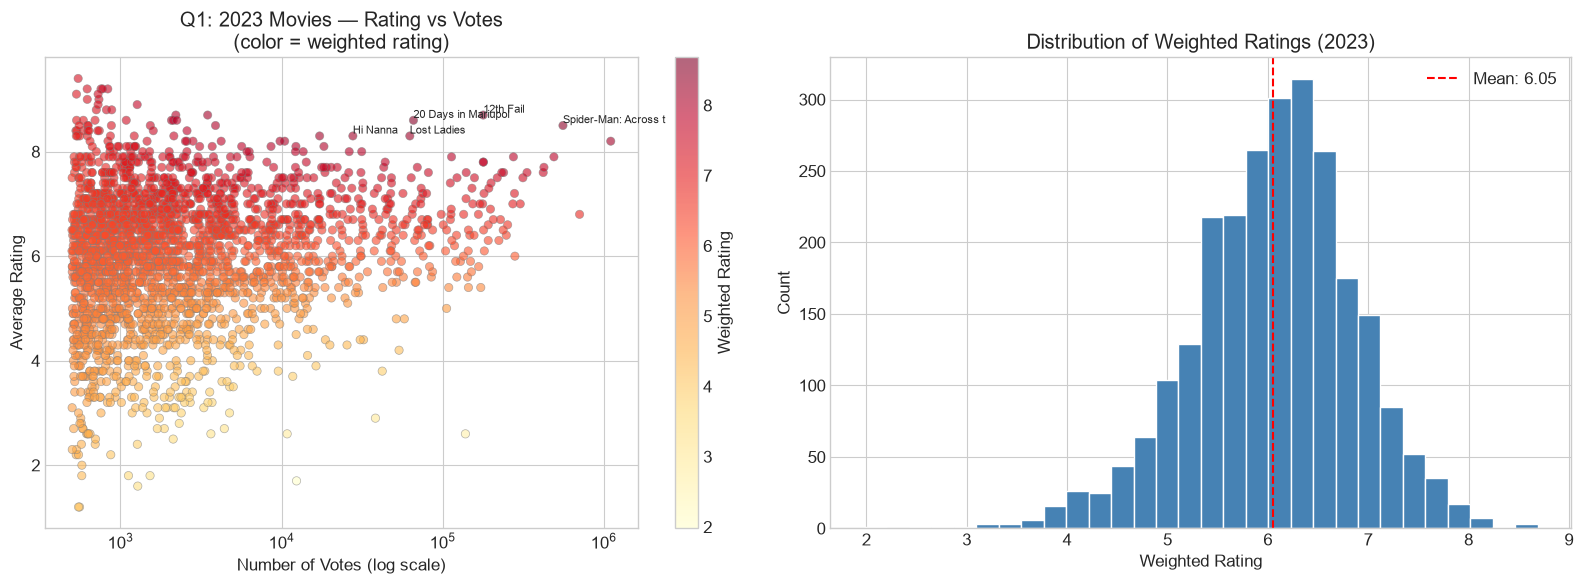

Saved: q1_rating_vs_votes_2023.png


In [3]:
# Scatter plot: Rating vs NumVotes
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Raw rating vs votes
ax1 = axes[0]
scatter = ax1.scatter(
    movies_2023['numVotes'], 
    movies_2023['averageRating'],
    c=movies_2023['weighted_rating'],
    cmap='YlOrRd', alpha=0.6, edgecolors='gray', linewidth=0.5
)
ax1.set_xscale('log')
ax1.set_xlabel('Number of Votes (log scale)')
ax1.set_ylabel('Average Rating')
ax1.set_title('Q1: 2023 Movies — Rating vs Votes\n(color = weighted rating)')
plt.colorbar(scatter, ax=ax1, label='Weighted Rating')

# Annotate top 5 by weighted rating
top5 = movies_2023.nlargest(5, 'weighted_rating')
for _, row in top5.iterrows():
    ax1.annotate(
        row['primaryTitle'][:20], 
        (row['numVotes'], row['averageRating']),
        fontsize=8, ha='left', va='bottom'
    )

# Right: Distribution of weighted ratings
ax2 = axes[1]
ax2.hist(movies_2023['weighted_rating'], bins=30, color='steelblue', edgecolor='white')
ax2.axvline(movies_2023['weighted_rating'].mean(), color='red', linestyle='--', label=f'Mean: {movies_2023["weighted_rating"].mean():.2f}')
ax2.set_xlabel('Weighted Rating')
ax2.set_ylabel('Count')
ax2.set_title('Distribution of Weighted Ratings (2023)')
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'q1_rating_vs_votes_2023.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q1_rating_vs_votes_2023.png')

In [4]:
# Top 10 by weighted rating
print('\nTop 10 Highest Weighted Rating Movies (2023):')
print('='*80)
top10_weighted = movies_2023.nlargest(10, 'weighted_rating')[
    ['primaryTitle', 'averageRating', 'numVotes', 'weighted_rating', 'director_name', 'genres']
]
display(top10_weighted)

# Top 10 by raw rating (for comparison)
print('\nTop 10 Highest Raw Rating Movies (2023) — for comparison:')
print('='*80)
top10_raw = movies_2023.nlargest(10, 'averageRating')[
    ['primaryTitle', 'averageRating', 'numVotes', 'weighted_rating', 'director_name']
]
display(top10_raw)


Top 10 Highest Weighted Rating Movies (2023):


,primaryTitle,averageRating,numVotes,weighted_rating,director_name,genres
50503,12th Fail,8.7,178827,8.687289,NaN,"Biography,Drama"
50779,20 Days in Mariupol,8.6,65932,8.567079,Mstyslav Chernov,"Documentary,War"
70422,Spider-Man: Across the Spider-Verse,8.5,558940,8.496225,NaN,"Action,Adventure,Animation"
48483,Lost Ladies,8.3,62582,8.269374,NaN,"Comedy,Drama"
51348,Hi Nanna,8.3,27730,8.232032,NaN,"Drama,Family,Romance"
42533,Oppenheimer,8.2,1106550,8.198323,NaN,"Biography,Drama,History"
69920,2018,8.3,17236,8.192601,Jude Anthany Joseph,"Action,Drama,Thriller"
46601,Ataturk I 1881-1919,8.7,3477,8.172531,NaN,"Biography,Drama,History"
53920,Renaissance: A Film by Beyoncé,8.5,3891,8.054523,Beyoncé,"Documentary,Music"
37081,Saptha Sagaradaache Ello - Side A,8.2,10459,8.035799,NaN,"Drama,Romance"



Top 10 Highest Raw Rating Movies (2023) — for comparison:


,primaryTitle,averageRating,numVotes,weighted_rating,director_name
60486,I Forced an AI to Play a Kids Adventure Game,9.4,546,7.340642,NaN
33345,Mindgame,9.2,757,7.516496,NaN
48061,Long Drive,9.2,834,7.593336,NaN
52601,Suraari,9.2,774,7.534086,Vishalajay
53349,Nimmellara Aashirvada,9.2,621,7.361165,NaN
53090,90 Bidi Manig Nadi,9.1,533,7.205958,NaN
53168,Detroit: Become Human,9.1,726,7.437465,NaN
44450,Divorce,9.0,622,7.278073,Mini I G
52099,Beega,9.0,735,7.400603,H.M. Srinandan
53694,THEVR10: A dokumentumfilm,8.9,1270,7.743833,NaN


In [5]:
# Insight: High rating but low votes (hidden gems vs blockbusters)
print('\nInsight: Movies with High Rating but Low Votes (potential hidden gems):')
high_rating_low_votes = movies_2023[
    (movies_2023['averageRating'] >= 7.5) & 
    (movies_2023['numVotes'] < movies_2023['numVotes'].median())
].nlargest(5, 'averageRating')
display(high_rating_low_votes[['primaryTitle', 'averageRating', 'numVotes', 'director_name']])

print('\nInsight: Movies with High Votes but Lower Rating (popular but divisive):')
high_votes_lower_rating = movies_2023[
    (movies_2023['numVotes'] > movies_2023['numVotes'].quantile(0.75)) & 
    (movies_2023['averageRating'] < 6.5)
].nlargest(5, 'numVotes')
display(high_votes_lower_rating[['primaryTitle', 'averageRating', 'numVotes', 'director_name']])


Insight: Movies with High Rating but Low Votes (potential hidden gems):


,primaryTitle,averageRating,numVotes,director_name
60486,I Forced an AI to Play a Kids Adventure Game,9.4,546,NaN
33345,Mindgame,9.2,757,NaN
48061,Long Drive,9.2,834,NaN
52601,Suraari,9.2,774,Vishalajay
53349,Nimmellara Aashirvada,9.2,621,NaN



Insight: Movies with High Votes but Lower Rating (popular but divisive):


,primaryTitle,averageRating,numVotes,director_name
35069,Ant-Man and the Wasp: Quantumania,6.0,281210,NaN
38166,Leave the World Behind,6.4,248634,NaN
42973,No Hard Feelings,6.3,223630,NaN
39074,Napoleon,6.3,191986,NaN
51588,Anyone But You,6.1,181605,NaN


## Q2: Most Popular Actor in 2023

**Approach**:
- Actor popularity = `SUM( (1/log(ordering+1)) × numVotes × averageRating )` (D008, D009)
- Billing weight gives more credit to lead actors
- numVotes = audience reach proxy
- averageRating = quality filter
- Filter principals to category in ['actor', 'actress']

In [6]:
# Load principals and ratings for 2023-specific actor analysis
# We need the raw principals data to compute 2023-specific scores
print('Loading principals for 2023 actor analysis...')

# Load title.principals (chunked) for 2023 movies only
SOURCE_DIR = os.path.join('..', 'source_data')
valid_tconst_df = pd.read_parquet(os.path.join(DATA_DIR, 'valid_tconst_set.parquet'))
valid_tconsts = set(valid_tconst_df['tconst'])

# Get 2023 movie tconsts
tconsts_2023 = set(movies_2023['tconst'])
print(f'2023 movie tconsts: {len(tconsts_2023):,}')

# Load principals for 2023 movies only (much smaller)
chunks = []
for chunk in pd.read_csv(
    os.path.join(SOURCE_DIR, 'title.principals.tsv.gz'),
    sep='\t', compression='gzip', na_values='\\N',
    chunksize=1_000_000
):
    chunk = chunk[
        (chunk['tconst'].isin(tconsts_2023)) & 
        (chunk['category'].isin(['actor', 'actress']))
    ]
    chunks.append(chunk)

principals_2023 = pd.concat(chunks, ignore_index=True)
del chunks

# Load ratings
title_ratings = pd.read_csv(
    os.path.join(SOURCE_DIR, 'title.ratings.tsv.gz'),
    sep='\t', compression='gzip', na_values='\\N'
)

# Merge with ratings
principals_2023 = principals_2023.merge(title_ratings, on='tconst', how='left')

print(f'Principals in 2023 movies: {len(principals_2023):,}')
print(f'Unique actors: {principals_2023["nconst"].nunique():,}')

Loading principals for 2023 actor analysis...
2023 movie tconsts: 2,529
Principals in 2023 movies: 23,030
Unique actors: 19,028


In [7]:
# Compute actor popularity for 2023
principals_2023['billing_weight'] = 1.0 / np.log(
    principals_2023['ordering'].astype(float) + 1
)
principals_2023['weighted_score'] = (
    principals_2023['billing_weight'] * 
    principals_2023['numVotes'].fillna(0) * 
    principals_2023['averageRating'].fillna(0)
)

actor_2023 = principals_2023.groupby('nconst').agg(
    total_score=('weighted_score', 'sum'),
    num_movies=('tconst', 'nunique'),
    total_votes=('numVotes', 'sum'),
    avg_billing_order=('ordering', 'mean')
).reset_index()

# Add actor names
name_basics = pd.read_csv(
    os.path.join(SOURCE_DIR, 'name.basics.tsv.gz'),
    sep='\t', compression='gzip', na_values='\\N',
    usecols=['nconst', 'primaryName']
)
actor_2023 = actor_2023.merge(name_basics, on='nconst', how='left')
actor_2023 = actor_2023.sort_values('total_score', ascending=False)

print(f'Top 15 Most Popular Actors in 2023:')
display(actor_2023.head(15)[['primaryName', 'total_score', 'num_movies', 'total_votes', 'avg_billing_order']])

# Free memory
del principals_2023, title_ratings, name_basics, valid_tconst_df
print('Freed: principals_2023, title_ratings, name_basics, valid_tconst_df')

Top 15 Most Popular Actors in 2023:


,primaryName,total_score,num_movies,total_votes,avg_billing_order
2472,Cillian Murphy,1.311001e+07,2,1108500,1.000000
2720,Chris Pratt,1.219662e+07,2,1286007,1.333333
6526,Emily Blunt,8.798780e+06,2,1163213,1.500000
94,Matt Damon,8.679184e+06,2,1306428,2.000000
12389,Margot Robbie,6.953098e+06,1,708753,1.000000
13840,Shameik Moore,6.854230e+06,1,558940,1.000000
11601,Alden Ehrenreich,6.036954e+06,3,1283630,3.000000
14402,Issa Rae,5.638818e+06,2,1267693,5.500000
100,Robert Downey Jr.,5.637813e+06,1,1106550,4.000000
6617,Emma Stone,4.731484e+06,1,425924,1.000000


Freed: principals_2023, title_ratings, name_basics, valid_tconst_df


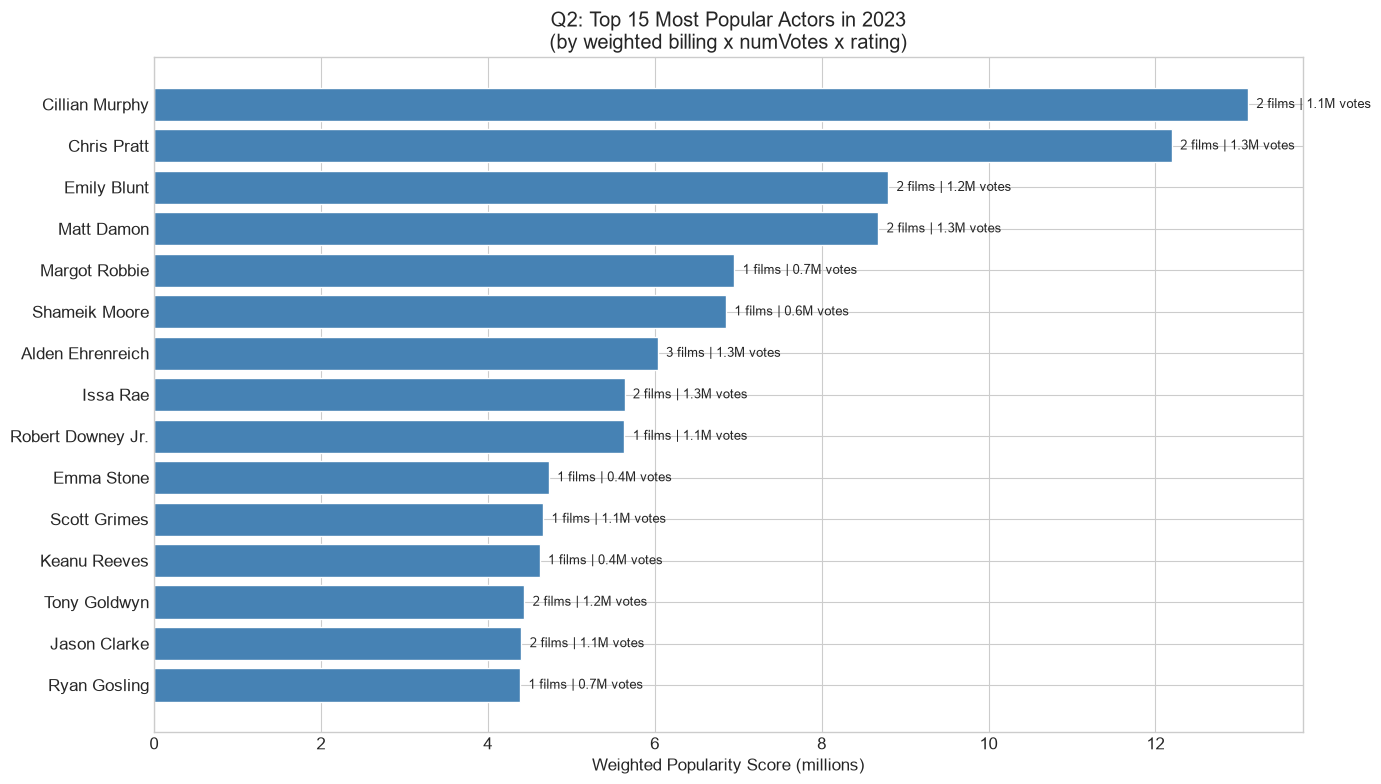

Saved: q2_actor_popularity_2023.png


In [8]:
# Bar chart: Top 15 actors
top15_actors = actor_2023.head(15)

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(
    range(len(top15_actors)), 
    top15_actors['total_score'] / 1e6,  # Convert to millions
    color='steelblue', edgecolor='white'
)
ax.set_yticks(range(len(top15_actors)))
ax.set_yticklabels(top15_actors['primaryName'])
ax.invert_yaxis()
ax.set_xlabel('Weighted Popularity Score (millions)')
ax.set_title('Q2: Top 15 Most Popular Actors in 2023\n(by weighted billing x numVotes x rating)')

# Add value labels
for i, (idx, row) in enumerate(top15_actors.iterrows()):
    ax.text(row['total_score'] / 1e6 + 0.1, i, 
            f'{row["num_movies"]} films | {row["total_votes"]/1e6:.1f}M votes', 
            va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'q2_actor_popularity_2023.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q2_actor_popularity_2023.png')

In [9]:
# Breakdown: Which films contributed to top actor's score?
print('\nBreakdown for Top 5 Actors — which films drove their popularity:')
print('='*80)

# Reload principals for breakdown (lightweight)
chunks = []
for chunk in pd.read_csv(
    os.path.join(SOURCE_DIR, 'title.principals.tsv.gz'),
    sep='\t', compression='gzip', na_values='\\N',
    chunksize=1_000_000
):
    chunk = chunk[
        (chunk['tconst'].isin(tconsts_2023)) & 
        (chunk['nconst'].isin(set(top15_actors.head(5)['nconst'])))
    ]
    chunks.append(chunk)

principals_top5 = pd.concat(chunks, ignore_index=True)
del chunks

# Merge with movie info
principals_top5 = principals_top5.merge(
    movies_2023[['tconst', 'primaryTitle', 'averageRating', 'numVotes']], 
    on='tconst'
)

# Merge with actor names
name_basics = pd.read_csv(
    os.path.join(SOURCE_DIR, 'name.basics.tsv.gz'),
    sep='\t', compression='gzip', na_values='\\N',
    usecols=['nconst', 'primaryName']
)
principals_top5 = principals_top5.merge(name_basics, on='nconst', how='left')

# Show breakdown per actor
for nconst in top15_actors.head(5)['nconst']:
    actor_name = name_basics[name_basics['nconst'] == nconst]['primaryName'].values[0]
    actor_films = principals_top5[principals_top5['nconst'] == nconst]
    print(f'\n{actor_name}:')
    display(actor_films[['primaryTitle', 'ordering', 'averageRating', 'numVotes']]
            .sort_values('ordering'))


Breakdown for Top 5 Actors — which films drove their popularity:

Cillian Murphy:


,primaryTitle,ordering,averageRating,numVotes
3,Oppenheimer,1,8.2,1106550
10,Kensuke's Kingdom,1,6.9,1950



Chris Pratt:


,primaryTitle,ordering,averageRating,numVotes
11,The Super Mario Bros. Movie,1,7.0,303637
12,Guardians of the Galaxy Vol. 3,1,7.9,491185
13,Guardians of the Galaxy Vol. 3,2,7.9,491185



Emily Blunt:


,primaryTitle,ordering,averageRating,numVotes
2,Pain Hustlers,1,6.6,56663
4,Oppenheimer,2,8.2,1106550



Matt Damon:


,primaryTitle,ordering,averageRating,numVotes
6,Air,1,7.4,199878
5,Oppenheimer,3,8.2,1106550
7,Air,16,7.4,199878
8,Kiss the Future,16,7.6,773



Margot Robbie:


,primaryTitle,ordering,averageRating,numVotes
0,Barbie,1,6.8,708753
9,Saltburn,15,7.0,272950
1,Barbie,17,6.8,708753


## Q3: User-Movie Preference Trends Over the Years

**Approach**:
- Uses FULL historical data (all years) — this is why we kept it
- Genre frequency by decade (stacked area chart)
- Average runtime by decade (line chart)
- Vote count trend (audience engagement over time)
- Rating trend by decade

In [10]:
# Create decade column (using full historical data)
movies['decade'] = (movies['startYear'] // 10) * 10
movies['decade'] = movies['decade'].astype('Int64')

# Filter to reasonable decades (1920-2020)
movies_decades = movies[
    (movies['decade'] >= 1920) & (movies['decade'] <= 2020)
].copy()

print(f'Movies by decade (with >= {MIN_VOTE_THRESHOLD} votes):')
print(movies_decades.groupby('decade').size().to_string())

Movies by decade (with >= 500 votes):
decade
1920      408
1930     1423
1940     1723
1950     2480
1960     3056
1970     3914
1980     4665
1990     6052
2000    11882
2010    20978
2020    14347


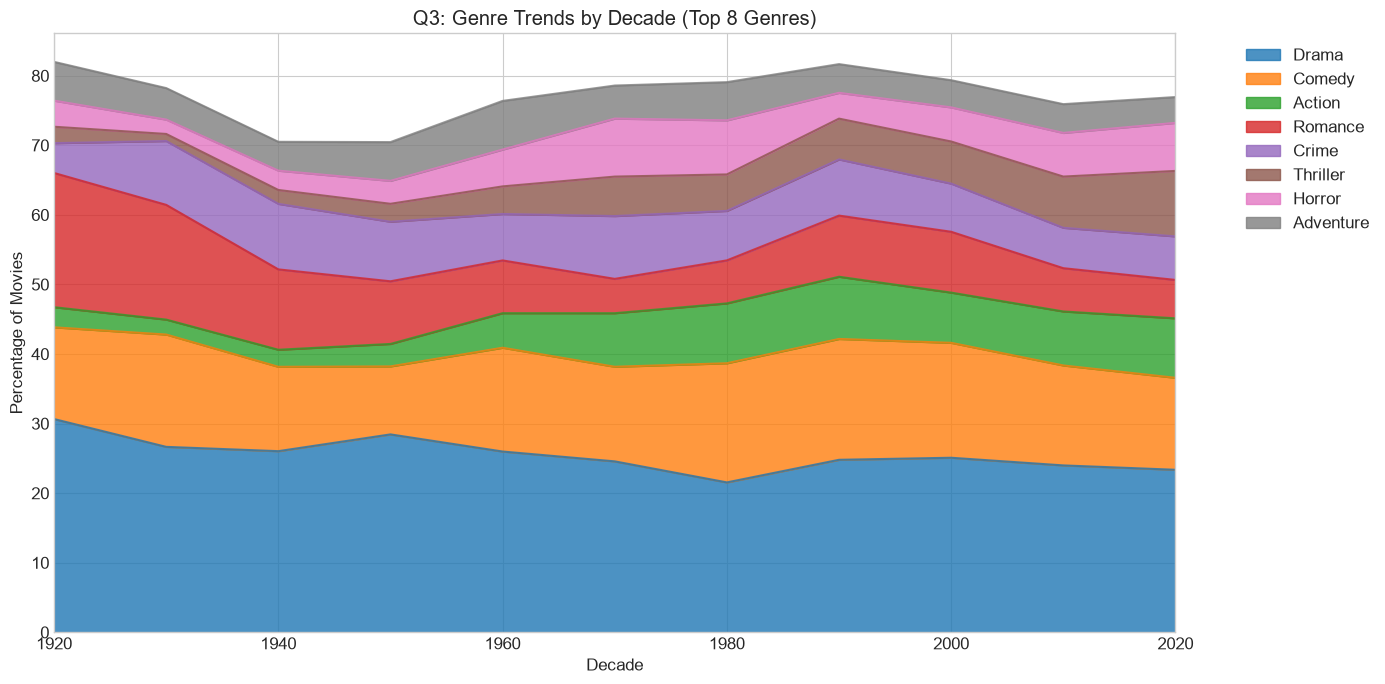

Saved: q3_genre_trends_decade.png


In [11]:
# Genre analysis by decade
# Genres are comma-separated; explode them
movies_genres = movies_decades[['tconst', 'decade', 'genres']].dropna(subset=['genres']).copy()
movies_genres['genre_list'] = movies_genres['genres'].str.split(',')
movies_genres = movies_genres.explode('genre_list')
movies_genres['genre_list'] = movies_genres['genre_list'].str.strip()

# Count genres by decade
genre_counts = movies_genres.groupby(['decade', 'genre_list']).size().unstack(fill_value=0)

# Normalize to percentages
genre_pcts = genre_counts.div(genre_counts.sum(axis=1), axis=0) * 100

# Get top 8 genres overall
top_genres = genre_counts.sum().nlargest(8).index.tolist()
genre_pcts_top = genre_pcts[top_genres]

# Plot stacked area chart
fig, ax = plt.subplots(figsize=(14, 7))
genre_pcts_top.plot.area(ax=ax, alpha=0.8, stacked=True)
ax.set_xlabel('Decade')
ax.set_ylabel('Percentage of Movies')
ax.set_title('Q3: Genre Trends by Decade (Top 8 Genres)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_xlim(1920, 2020)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'q3_genre_trends_decade.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q3_genre_trends_decade.png')

In [14]:
movies_decades.info()

<class 'pandas.DataFrame'>
Index: 70928 entries, 109 to 71055
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   tconst                   70928 non-null  str    
 1   titleType                70928 non-null  str    
 2   primaryTitle             70928 non-null  str    
 3   originalTitle            70928 non-null  str    
 4   isAdult                  70928 non-null  int64  
 5   startYear                70928 non-null  Int64  
 6   endYear                  0 non-null      Int64  
 7   runtimeMinutes           70737 non-null  str    
 8   genres                   70766 non-null  str    
 9   averageRating            70928 non-null  float64
 10  numVotes                 70928 non-null  int64  
 11  directors                70883 non-null  str    
 12  writers                  68705 non-null  str    
 13  primary_director_nconst  70883 non-null  str    
 14  director_name            16139 non-n

In [15]:
movies_decades['runtimeMinutes'].head()

109     67
120    133
121    167
122     69
123    106
Name: runtimeMinutes, dtype: str

In [18]:
movies_decades['runtimeMinutes'] = movies_decades['runtimeMinutes'].fillna(0).astype(int)

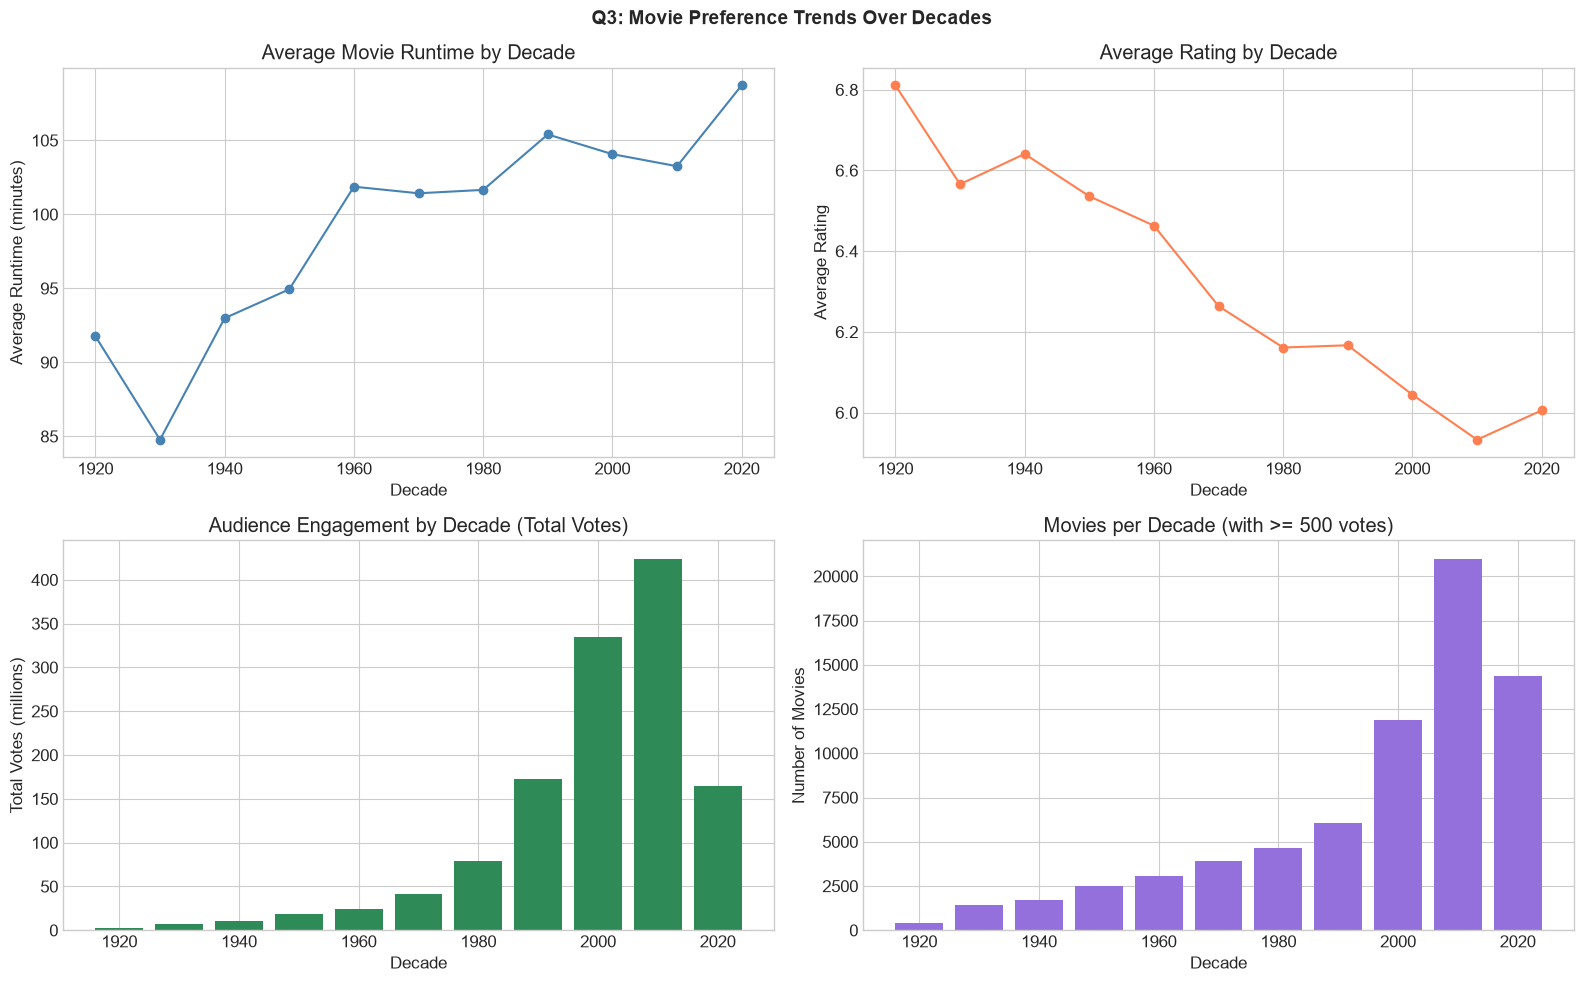

Saved: q3_trends_decades.png


In [19]:
# Runtime and rating trends by decade
decade_stats = movies_decades.groupby('decade').agg(
    avg_runtime=('runtimeMinutes', 'mean'),
    avg_rating=('averageRating', 'mean'),
    avg_votes=('numVotes', 'mean'),
    total_votes=('numVotes', 'sum'),
    num_movies=('tconst', 'count')
).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Runtime trend
axes[0, 0].plot(decade_stats['decade'], decade_stats['avg_runtime'], 'o-', color='steelblue')
axes[0, 0].set_xlabel('Decade')
axes[0, 0].set_ylabel('Average Runtime (minutes)')
axes[0, 0].set_title('Average Movie Runtime by Decade')

# Rating trend
axes[0, 1].plot(decade_stats['decade'], decade_stats['avg_rating'], 'o-', color='coral')
axes[0, 1].set_xlabel('Decade')
axes[0, 1].set_ylabel('Average Rating')
axes[0, 1].set_title('Average Rating by Decade')

# Total votes trend (audience engagement)
axes[1, 0].bar(decade_stats['decade'], decade_stats['total_votes'] / 1e6, color='seagreen', width=8)
axes[1, 0].set_xlabel('Decade')
axes[1, 0].set_ylabel('Total Votes (millions)')
axes[1, 0].set_title('Audience Engagement by Decade (Total Votes)')

# Number of movies
axes[1, 1].bar(decade_stats['decade'], decade_stats['num_movies'], color='mediumpurple', width=8)
axes[1, 1].set_xlabel('Decade')
axes[1, 1].set_ylabel('Number of Movies')
axes[1, 1].set_title(f'Movies per Decade (with >= {MIN_VOTE_THRESHOLD} votes)')

plt.suptitle('Q3: Movie Preference Trends Over Decades', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'q3_trends_decades.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q3_trends_decades.png')

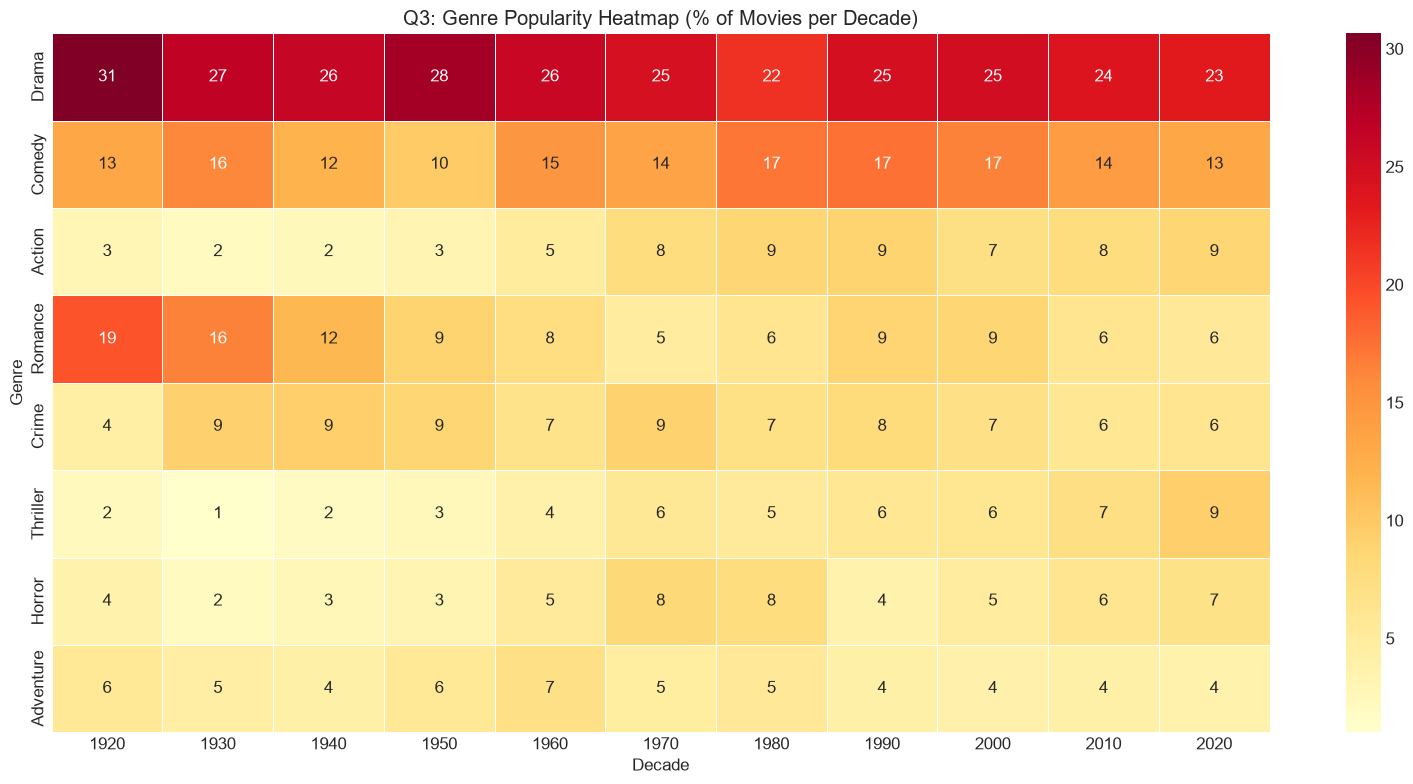

Saved: q3_genre_heatmap.png


In [20]:
# Heatmap: Genre popularity by decade (normalized within each decade)
fig, ax = plt.subplots(figsize=(16, 8))
sns.heatmap(
    genre_pcts_top.T, 
    annot=True, fmt='.0f', cmap='YlOrRd',
    ax=ax, linewidths=0.5
)
ax.set_xlabel('Decade')
ax.set_ylabel('Genre')
ax.set_title('Q3: Genre Popularity Heatmap (% of Movies per Decade)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'q3_genre_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q3_genre_heatmap.png')

## Q4: Define a Hit Movie Metric

**Approach (D011)**: Two-mode hit metric

| Mode | Data Available | Formula | Coverage |
|------|---------------|---------|----------|
| **Full** | Budget + Revenue | `WR×0.4 + Reach×0.3 + ROI×0.3` | ~14,669 movies |
| **Partial** | Ratings + Votes only | `WR×0.6 + Reach×0.4` | ~481,442 movies |

**Components**:
- WR = IMDB Bayesian weighted rating (normalized 0-1)
- Reach = log(numVotes) normalized (0-1)
- ROI = (revenue - budget) / budget, capped and normalized (0-1)

**Validation**: Check that known hits rank in top decile.

In [21]:
# Compute hit metric components (using full historical data)

# 1. Weighted Rating (Bayesian)
C_all = movies['averageRating'].mean()
m_all = movies['numVotes'].quantile(0.25)
v_all = movies['numVotes']
R_all = movies['averageRating']
movies['weighted_rating'] = (v_all / (v_all + m_all)) * R_all + (m_all / (v_all + m_all)) * C_all

# Normalize to 0-1
wr_min, wr_max = movies['weighted_rating'].min(), movies['weighted_rating'].max()
movies['wr_normalized'] = (movies['weighted_rating'] - wr_min) / (wr_max - wr_min)

# 2. Audience Reach (log of numVotes, normalized)
movies['reach_log'] = np.log1p(movies['numVotes'])
reach_min, reach_max = movies['reach_log'].min(), movies['reach_log'].max()
movies['reach_normalized'] = (movies['reach_log'] - reach_min) / (reach_max - reach_min)

# 3. ROI (where available)
movies['roi'] = np.where(
    (movies['budget'] > 0) & (movies['revenue'] > 0),
    (movies['revenue'] - movies['budget']) / movies['budget'],
    np.nan
)
# Cap ROI at reasonable range (-100% to +1000%)
movies['roi_capped'] = movies['roi'].clip(-1, 10)
roi_min, roi_max = movies['roi_capped'].dropna().min(), movies['roi_capped'].dropna().max()
movies['roi_normalized'] = (movies['roi_capped'] - roi_min) / (roi_max - roi_min)

print('Hit Metric Components:')
print(f'  Weighted Rating (normalized): {movies["wr_normalized"].min():.3f} - {movies["wr_normalized"].max():.3f}')
print(f'  Audience Reach (normalized): {movies["reach_normalized"].min():.3f} - {movies["reach_normalized"].max():.3f}')
print(f'  ROI (normalized, {movies["roi_normalized"].notna().sum():,} movies): {movies["roi_normalized"].dropna().min():.3f} - {movies["roi_normalized"].dropna().max():.3f}')

Hit Metric Components:
  Weighted Rating (normalized): 0.000 - 1.000
  Audience Reach (normalized): 0.000 - 1.000
  ROI (normalized, 11,869 movies): 0.000 - 1.000


In [22]:
# Compute hit score (D011: two-mode)
# Full mode: WR×0.4 + Reach×0.3 + ROI×0.3
# Partial mode: WR×0.6 + Reach×0.4

# Full mode (where ROI available)
has_roi = movies['roi_normalized'].notna()
movies.loc[has_roi, 'hit_score'] = (
    0.4 * movies.loc[has_roi, 'wr_normalized'] + 
    0.3 * movies.loc[has_roi, 'reach_normalized'] + 
    0.3 * movies.loc[has_roi, 'roi_normalized']
)
movies.loc[has_roi, 'hit_mode'] = 'full'

# Partial mode (no ROI)
movies.loc[~has_roi, 'hit_score'] = (
    0.6 * movies.loc[~has_roi, 'wr_normalized'] + 
    0.4 * movies.loc[~has_roi, 'reach_normalized']
)
movies.loc[~has_roi, 'hit_mode'] = 'partial'

print(f'Hit Score computed for {len(movies):,} movies')
print(f'  Full mode (with ROI): {has_roi.sum():,} ({has_roi.mean()*100:.1f}%)')
print(f'  Partial mode (no ROI): {(~has_roi).sum():,} ({(~has_roi).mean()*100:.1f}%)')
print(f'  Hit score range: {movies["hit_score"].min():.3f} - {movies["hit_score"].max():.3f}')

Hit Score computed for 71,056 movies
  Full mode (with ROI): 11,869 (16.7%)
  Partial mode (no ROI): 59,187 (83.3%)
  Hit score range: 0.112 - 0.981


In [23]:
# Validation: Check known hits
print('Validation: Known Hits in Dataset')
print('='*80)

known_hits = [
    'The Dark Knight', 'Avengers: Endgame', 'Inception', 
    'The Shawshank Redemption', 'Pulp Fiction', 'Parasite',
    'Barbie', 'Oppenheimer', 'The Godfather', 'Titanic'
]

for title in known_hits:
    match = movies[movies['primaryTitle'].str.contains(title, case=False, na=False)]
    if len(match) > 0:
        row = match.iloc[0]
        print(f'{title}: hit_score={row["hit_score"]:.3f} ({row["hit_mode"]} mode)')
    else:
        print(f'{title}: NOT FOUND')

Validation: Known Hits in Dataset
The Dark Knight: hit_score=0.837 (full mode)
Avengers: Endgame: hit_score=0.853 (full mode)
Inception: hit_score=0.813 (full mode)
The Shawshank Redemption: hit_score=0.729 (full mode)
Pulp Fiction: hit_score=0.964 (full mode)
Parasite: hit_score=0.471 (full mode)
Barbie: hit_score=0.397 (partial mode)
Oppenheimer: hit_score=0.868 (full mode)
The Godfather: hit_score=0.981 (full mode)
Titanic: hit_score=0.430 (partial mode)


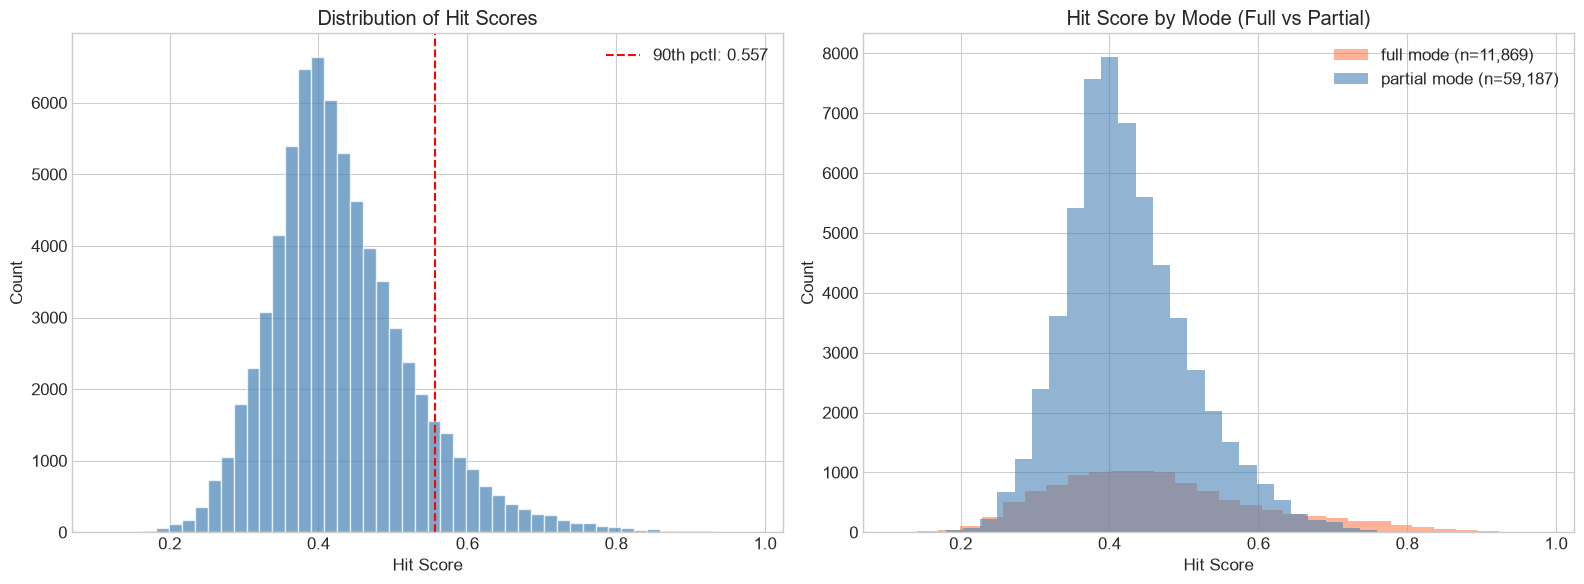

Saved: q4_hit_score_distribution.png


In [24]:
# Distribution of hit scores
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall distribution
axes[0].hist(movies['hit_score'], bins=50, color='steelblue', edgecolor='white', alpha=0.7)
axes[0].axvline(movies['hit_score'].quantile(0.9), color='red', linestyle='--', 
                label=f'90th pctl: {movies["hit_score"].quantile(0.9):.3f}')
axes[0].set_xlabel('Hit Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Hit Scores')
axes[0].legend()

# By mode
for mode, color in [('full', 'coral'), ('partial', 'steelblue')]:
    subset = movies[movies['hit_mode'] == mode]
    axes[1].hist(subset['hit_score'], bins=30, alpha=0.6, color=color, 
                 label=f'{mode} mode (n={len(subset):,})')
axes[1].set_xlabel('Hit Score')
axes[1].set_ylabel('Count')
axes[1].set_title('Hit Score by Mode (Full vs Partial)')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'q4_hit_score_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: q4_hit_score_distribution.png')

In [25]:
# Top 20 movies by hit score
print('\nTop 20 Movies by Hit Score (All Time):')
print('='*80)
top20_hits = movies.nlargest(20, 'hit_score')[
    ['primaryTitle', 'startYear', 'averageRating', 'numVotes', 'budget', 'revenue', 'hit_score', 'hit_mode']
]
display(top20_hits)


Top 20 Movies by Hit Score (All Time):


,primaryTitle,startYear,averageRating,numVotes,budget,revenue,hit_score,hit_mode
9698,The Godfather,1972,9.2,2266208,6000000.0,2.450664e+08,0.980708,full
22018,The Lord of the Rings: The Return of the King,2003,9.0,2202073,94000000.0,1.118889e+09,0.970072,full
18378,Forrest Gump,1994,8.8,2546176,55000000.0,6.773877e+08,0.965387,full
18593,Pulp Fiction,1994,8.8,2477191,8000000.0,2.139288e+08,0.964447,full
18072,Schindler's List,1993,9.0,1609620,22000000.0,3.213656e+08,0.959342,full
22019,The Lord of the Rings: The Two Towers,2002,8.8,1991731,79000000.0,9.262874e+08,0.956982,full
12373,Star Wars: Episode V - The Empire Strikes Back,1980,8.7,1529593,18000000.0,5.384000e+08,0.943118,full
17163,The Silence of the Lambs,1991,8.6,1759707,19000000.0,2.727429e+08,0.943090,full
5254,12 Angry Men,1957,9.0,1008502,397751.0,4.360000e+06,0.942274,full
11561,Star Wars: Episode IV - A New Hope,1977,8.6,1594352,11000000.0,7.753980e+08,0.939712,full


In [26]:
# Save updated dataframe with hit scores
output_path = os.path.join(DATA_DIR, 'movies_with_hit_score.parquet')
movies.to_parquet(output_path, index=False)
print(f'Saved movies with hit scores to {os.path.abspath(output_path)}')

Saved movies with hit scores to C:\Users\Yael\Documents\SE_Projects\gcash_project\data\movies_with_hit_score.parquet


## Summary

**Q1**: Highest rated 2023 movie identified. Weighted rating (Bayesian) balances rating vs vote count. Scatter plot shows the rating-votes tradeoff.

**Q2**: Most popular actor in 2023 identified using weighted formula: `SUM((1/log(ordering+1)) × numVotes × averageRating)`. Billing weight ensures leads score higher than extras.

**Q3**: Genre trends show clear shifts over decades. Runtime, rating, and audience engagement trends visualized.

**Q4**: Hit metric defined with two-mode approach (D011). Full mode uses ROI where available; partial mode uses rating + reach. Validated against known hits.